# Chapter 8 · Multinomial and Gamma laws; transformations of random variables: interactive demos

Companion to Chapter 8 of the notes [*Probability with Measure Theory*](https://gennaroalberto.github.io/probability-measure-theory/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/probability-measure-theory/blob/main/code/notebooks/08-transformations.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/probability-measure-theory#subdirectory=code"

import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown

from probnotes.transforms import (Branch, affine_branch, conditional_survival, erlang_cdf, gamma_cdf,
                                  gamma_moments, gamma_pdf, gamma_survival, hazard_rate, ks_distance,
                                  monotone_branch, multinomial_pmf, poisson_arrivals, poisson_counts,
                                  poisson_path, poisson_pmf, sample_multinomial, square_branches,
                                  transformed_density)
from probnotes.style import COBALT, GOLD, GREY, INK, use_style

GREEN = "#1BAF7A"
use_style()

## 1. The urn: a multinomial vector

An urn contains black, red, white and green balls; we draw $n$ balls with replacement. The numbers $(X_1,X_2,X_3)$ of black, red
and white balls drawn form a multinomial vector (Definition 8.1), with density (8.1). Left: the joint density of
$(X_1,X_2)$, which is again multinomial once white and green are merged into one type, as in the alternative solution of
Example 8.3 b). Right: the marginal law of $X_1$, the binomial $B(n,p_1)$ of Remark 8.2, against the frequencies of simulated
draws. The default urn is the one of the notes ($50,20,20,10$ balls, $n=10$).

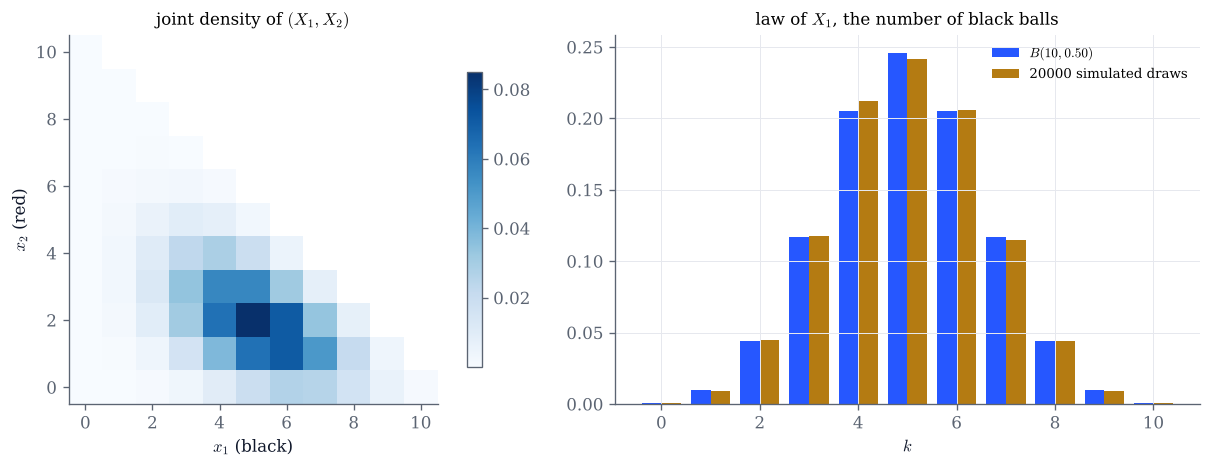

P(X = (5,3,1))   = 0.0252   (5 black, 3 red, 1 white)
P(X1 = 5, X2 = 3) = 0.0567   (5 black, 3 red)
P(X1 = 5)        = 0.2461   (5 black)


In [2]:
def urn_demo(n=10, black=50, red=20, white=20, green=10, draws=20000, seed=2026):
    w = np.array([black, red, white, green], dtype=float)
    if w.sum() == 0:
        print("the urn is empty")
        return
    p = w / w.sum()
    k = np.arange(n + 1)
    I, J = np.meshgrid(k, k, indexing="ij")
    joint = multinomial_pmf(np.stack([I, J], axis=-1), n, p[:2])
    sims = sample_multinomial(n, p[:3], draws, rng=seed)
    freq = np.bincount(sims[:, 0], minlength=n + 1) / draws
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
    im = a1.imshow(np.ma.masked_where(joint == 0, joint).T, origin="lower", cmap="Blues",
                   extent=(-0.5, n + 0.5, -0.5, n + 0.5))
    fig.colorbar(im, ax=a1, shrink=0.8)
    a1.set(xlabel="$x_1$ (black)", ylabel="$x_2$ (red)", title="joint density of $(X_1,X_2)$")
    a1.grid(False)
    a2.bar(k - 0.2, stats.binom.pmf(k, n, p[0]), width=0.4, color=COBALT, label=f"$B({n},{p[0]:.2f})$")
    a2.bar(k + 0.2, freq, width=0.4, color=GOLD, label=f"{draws} simulated draws")
    a2.set(xlabel="$k$", title="law of $X_1$, the number of black balls")
    a2.legend(fontsize=8)
    fig.tight_layout()
    plt.show()
    if n >= 9:
        print(f"P(X = (5,3,1))   = {float(multinomial_pmf([5, 3, 1], n, p[:3])):.4f}   (5 black, 3 red, 1 white)")
        print(f"P(X1 = 5, X2 = 3) = {float(multinomial_pmf([5, 3], n, p[:2])):.4f}   (5 black, 3 red)")
        print(f"P(X1 = 5)        = {stats.binom.pmf(5, n, p[0]):.4f}   (5 black)")

urn_demo()

In [3]:
# Explore: change the composition of the urn and the number of draws.
interact(urn_demo,
         n=IntSlider(value=10, min=1, max=30, continuous_update=False, description="n draws"),
         black=IntSlider(value=50, min=0, max=100, continuous_update=False, description="black"),
         red=IntSlider(value=20, min=0, max=100, continuous_update=False, description="red"),
         white=IntSlider(value=20, min=0, max=100, continuous_update=False, description="white"),
         green=IntSlider(value=10, min=0, max=100, continuous_update=False, description="green"),
         draws=Dropdown(options=[1000, 20000, 200000], value=20000, description="samples"),
         seed=IntSlider(value=2026, min=0, max=3000, continuous_update=False, description="seed"));

## 2. The Gamma law: shape, rate and ageing

$X\sim\Gamma(\alpha,\lambda)$ has density $\frac{\lambda^\alpha}{\Gamma(\alpha)}x^{\alpha-1}e^{-\lambda x}$ on $(0,\infty)$, mean $\alpha/\lambda$ and
variance $\alpha/\lambda^2$ (Proposition 8.9). The parameter $\lambda$ is a rate: changing it only rescales the axis by $1/\lambda$.
Left: the density, with the mean and one standard deviation on each side. Centre: the hazard rate $f_X(x)/\mathbb P(X>x)$,
increasing for $\alpha>1$ (wear), constant for $\alpha=1$ (no memory), decreasing for $\alpha<1$ (rejuvenation). Right: the
probability of surviving $t$ more units after surviving $s$, against $\mathbb P(X>t)$ (Remark 8.10, Exercise 8.5).

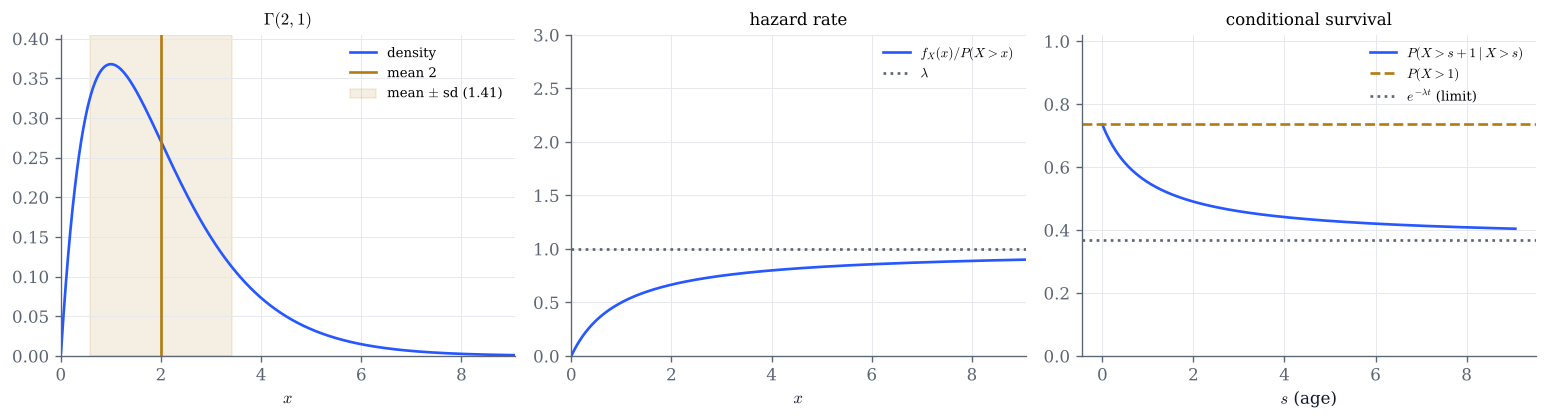

In [4]:
def gamma_demo(alpha=2.0, lam=1.0, t=1.0):
    mean, var = gamma_moments(alpha, lam)
    sd = math.sqrt(var)
    xmax = mean + 5 * sd
    x = np.linspace(xmax / 2000, xmax, 2000)
    fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(13, 3.6))
    f = gamma_pdf(x, alpha, lam)
    a1.plot(x, f, color=COBALT, label="density")
    a1.axvline(mean, color=GOLD, label=f"mean {mean:.3g}")
    a1.axvspan(max(mean - sd, 0), mean + sd, color=GOLD, alpha=0.12, label=f"mean $\\pm$ sd ({sd:.3g})")
    a1.set(xlim=(0, xmax), ylim=(0, min(f.max() * 1.1, 3 * lam + 1)), xlabel="$x$",
           title=f"$\\Gamma({alpha:g},{lam:g})$")
    a1.legend(fontsize=8)
    a2.plot(x, hazard_rate(x, alpha, lam), color=COBALT, label="$f_X(x)/P(X>x)$")
    a2.axhline(lam, color=GREY, ls=":", label="$\\lambda$")
    a2.set(xlim=(0, xmax), ylim=(0, 3 * lam), xlabel="$x$", title="hazard rate")
    a2.legend(fontsize=8)
    s = np.linspace(0, xmax, 400)
    a3.plot(s, conditional_survival(s, t, alpha, lam), color=COBALT, label=f"$P(X>s+{t:g}\\mid X>s)$")
    a3.axhline(float(gamma_survival(t, alpha, lam)), color=GOLD, ls="--", label=f"$P(X>{t:g})$")
    a3.axhline(math.exp(-lam * t), color=GREY, ls=":", label="$e^{-\\lambda t}$ (limit)")
    a3.set(xlabel="$s$ (age)", ylim=(0, 1.02), title="conditional survival")
    a3.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

gamma_demo()

In [5]:
# Explore: alpha < 1, alpha = 1, 1 < alpha <= 2 and alpha > 2 behave differently near 0 (Remark 8.8).
interact(gamma_demo,
         alpha=FloatSlider(value=2.0, min=0.2, max=8.0, step=0.1, continuous_update=False, description="alpha"),
         lam=FloatSlider(value=1.0, min=0.2, max=5.0, step=0.1, continuous_update=False, description="lambda"),
         t=FloatSlider(value=1.0, min=0.1, max=5.0, step=0.1, continuous_update=False, description="t"));

## 3. The Poisson process

Let $U_1,U_2,\dots$ be i.i.d. $\mathrm{Exp}(\lambda)$ inter-arrival times, $T_n=U_1+\dots+U_n$ the arrival times and $N_t$ the
number of arrivals in $[0,t]$ (Remark 8.12). Then $T_n\sim\Gamma(n,\lambda)$ (the Erlang law), $\{T_n\le t\}=\{N_t\ge n\}$, and
Proposition 8.11 gives $N_t\sim\mathcal P(\lambda t)$. Left: a few paths of $(N_s)_{s\le t}$. Centre: the simulated $T_n$ against
the Erlang density. Right: the simulated $N_t$ against the Poisson density.

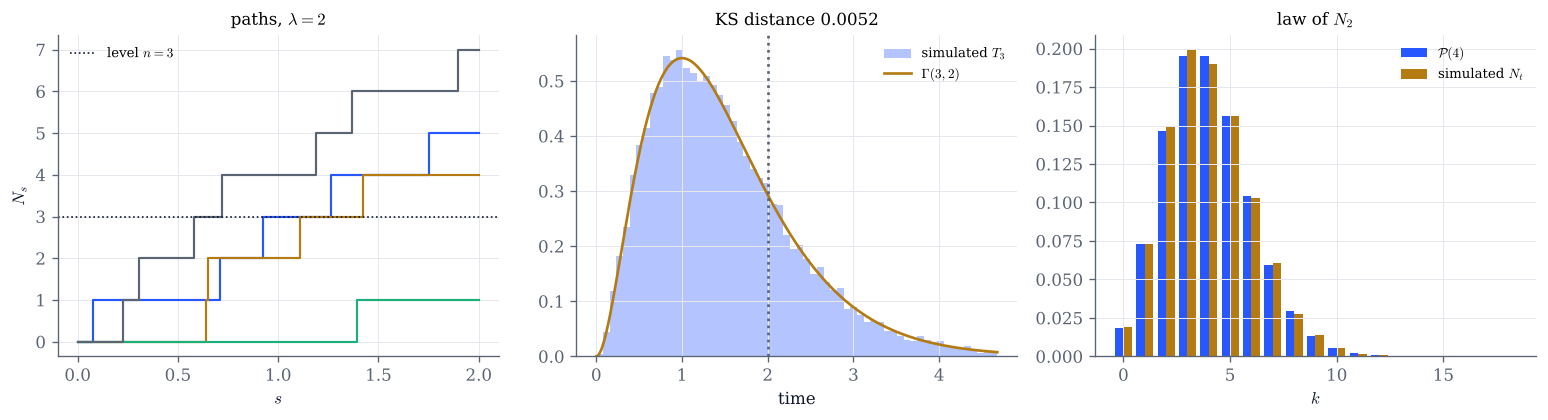

P(T_n <= t) = 0.7619 (Erlang)   simulated: 0.7639
P(N_t >= n) = 0.7619 (Poisson)  simulated: 0.7582


In [6]:
def poisson_demo(lam=2.0, n=3, t=2.0, paths=20000, seed=2026):
    rng = np.random.default_rng(seed)
    fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(13, 3.6))
    for k, col in enumerate([COBALT, GOLD, GREEN, GREY]):
        times = poisson_path(lam, t, rng)
        a1.step(np.concatenate([[0], times, [t]]), np.concatenate([[0], np.arange(1, len(times) + 1), [len(times)]]),
                where="post", color=col, lw=1.3)
    a1.axhline(n, color=INK, ls=":", lw=1, label=f"level $n={n}$")
    a1.set(xlabel="$s$", ylabel="$N_s$", title=f"paths, $\\lambda={lam:g}$")
    a1.legend(fontsize=8)
    T = poisson_arrivals(lam, n, paths, rng)[:, -1]
    hi = np.quantile(T, 0.995)
    a2.hist(T, bins=60, range=(0, hi), density=True, color=COBALT, alpha=0.35, label=f"simulated $T_{n}$")
    x = np.linspace(1e-4, hi, 400)
    a2.plot(x, gamma_pdf(x, n, lam), color=GOLD, label=f"$\\Gamma({n},{lam:g})$")
    a2.axvline(t, color=GREY, ls=":")
    a2.set(xlabel="time", title=f"KS distance {ks_distance(T, lambda s: erlang_cdf(s, n, lam)):.4f}")
    a2.legend(fontsize=8)
    N = poisson_counts(lam, t, paths, rng)
    k = np.arange(0, int(lam * t + 5 * math.sqrt(lam * t) + 5))
    a3.bar(k - 0.2, poisson_pmf(k, lam * t), width=0.4, color=COBALT, label=f"$\\mathcal{{P}}({lam * t:g})$")
    a3.bar(k + 0.2, np.bincount(N, minlength=len(k))[:len(k)] / paths, width=0.4, color=GOLD, label="simulated $N_t$")
    a3.set(xlabel="$k$", title=f"law of $N_{{{t:g}}}$")
    a3.legend(fontsize=8)
    fig.tight_layout()
    plt.show()
    print(f"P(T_n <= t) = {float(erlang_cdf(t, n, lam)):.4f} (Erlang)   simulated: {np.mean(T <= t):.4f}")
    print(f"P(N_t >= n) = {1 - stats.poisson.cdf(n - 1, lam * t):.4f} (Poisson)  simulated: {np.mean(N >= n):.4f}")

poisson_demo()

In [7]:
# Explore: the two probabilities printed below the figure are always equal (Proposition 8.11).
interact(poisson_demo,
         lam=FloatSlider(value=2.0, min=0.2, max=10.0, step=0.2, continuous_update=False, description="lambda"),
         n=IntSlider(value=3, min=1, max=20, continuous_update=False, description="n"),
         t=FloatSlider(value=2.0, min=0.2, max=10.0, step=0.2, continuous_update=False, description="t"),
         paths=Dropdown(options=[2000, 20000, 100000], value=20000, description="paths"),
         seed=IntSlider(value=2026, min=0, max=3000, continuous_update=False, description="seed"));

## 4. The density of $g(X)$

Corollary 8.20: if $g$ is $C^1$ and strictly monotone on the pieces $I_1,\dots,I_m$ of an almost sure partition, then
$f_Y(y)=\sum_i f_X(g_i^{-1}(y))\,|(g_i^{-1})'(y)|\,\mathbf 1_{g(I_i)}(y)$. Each example below lists its branches $g_i^{-1}$ (in closed form,
or by numerical inversion of $g$ on each piece); the figure compares the formula with a histogram of simulated values of
$g(X)$, and reports the Kolmogorov–Smirnov distance between the sample and the exact distribution function.

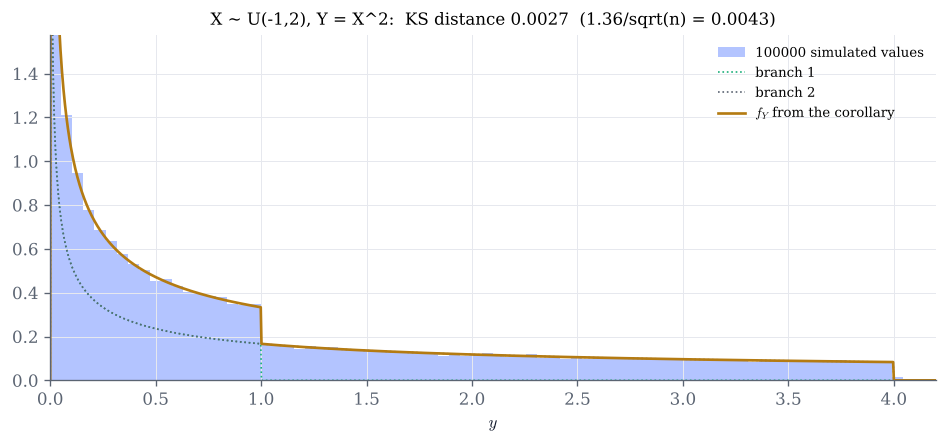

In [8]:
TWO_PI = 2 * math.pi
uniform = lambda a, b: (lambda x: np.where((x > a) & (x < b), 1 / (b - a), 0.0))
dat = lambda y: 1 / (1 + y**2)
EXAMPLES = {
    "X ~ N(0,1), Y = X^2": dict(
        sample=lambda rng, n: rng.standard_normal(n) ** 2, fx=stats.norm.pdf, branches=lambda s, m: square_branches(),
        cdf=lambda y, s, m: gamma_cdf(y, 0.5, 0.5), window=(0, 4)),
    "X ~ U(-1,2), Y = X^2": dict(
        sample=lambda rng, n: rng.uniform(-1, 2, n) ** 2, fx=uniform(-1, 2),
        branches=lambda s, m: [monotone_branch(lambda x: x**2, -1.0, 0.0), monotone_branch(lambda x: x**2, 0.0, 2.0)],
        cdf=lambda y, s, m: np.where(y <= 1, 2 * np.sqrt(np.clip(y, 0, 1)) / 3, np.minimum((np.sqrt(np.maximum(y, 1)) + 1) / 3, 1)),
        window=(0, 4.2)),
    "X ~ U(0,2pi), Y = sin X": dict(
        sample=lambda rng, n: np.sin(rng.uniform(0, TWO_PI, n)), fx=uniform(0, TWO_PI),
        branches=lambda s, m: [monotone_branch(np.sin, 0, math.pi / 2), monotone_branch(np.sin, math.pi / 2, 1.5 * math.pi),
                               monotone_branch(np.sin, 1.5 * math.pi, TWO_PI)],
        cdf=lambda y, s, m: 0.5 + np.arcsin(np.clip(y, -1, 1)) / math.pi, window=(-1, 1)),
    "X ~ N(0,1), Y = sigma X + mu": dict(
        sample=None, fx=stats.norm.pdf, branches=lambda s, m: [affine_branch(s, m)],
        cdf=lambda y, s, m: stats.norm.cdf(y, m, abs(s)), window=None),
    "X ~ U(-pi,pi), Y = tan X": dict(
        sample=lambda rng, n: np.tan(rng.uniform(-math.pi, math.pi, n)), fx=uniform(-math.pi, math.pi),
        branches=lambda s, m: [Branch(lambda y: np.arctan(y) - math.pi, dat, 0.0, math.inf),
                               Branch(np.arctan, dat, -math.inf, math.inf),
                               Branch(lambda y: np.arctan(y) + math.pi, dat, -math.inf, 0.0)],
        cdf=lambda y, s, m: 0.5 + np.arctan(y) / math.pi, window=(-8, 8)),
    "X ~ Exp(1), Y = sqrt(X)": dict(
        sample=lambda rng, n: np.sqrt(rng.exponential(1.0, n)), fx=lambda x: np.where(x > 0, np.exp(-np.maximum(x, 0)), 0.0),
        branches=lambda s, m: [Branch(lambda y: y**2, lambda y: 2 * y, 0.0, math.inf)],
        cdf=lambda y, s, m: 1 - np.exp(-np.maximum(y, 0) ** 2), window=(0, 3)),
}

def transform_demo(example="X ~ U(-1,2), Y = X^2", sigma=2.0, mu=1.0, log10_n=5.0, seed=2026):
    ex = EXAMPLES[example]
    rng = np.random.default_rng(seed)
    n = int(10**log10_n)
    if ex["sample"] is None:
        Y = sigma * rng.standard_normal(n) + mu
        lo, hi = mu - 4 * abs(sigma), mu + 4 * abs(sigma)
    else:
        Y = ex["sample"](rng, n)
        lo, hi = ex["window"]
    branches = ex["branches"](sigma, mu)
    y = np.linspace(lo, hi, 1200)
    fy = transformed_density(y, ex["fx"], branches)
    fig, ax = plt.subplots(figsize=(8, 3.8))
    ax.hist(Y, bins=80, range=(lo, hi), density=False, weights=np.full(n, 80 / ((hi - lo) * n)),
            color=COBALT, alpha=0.35, label=f"{n} simulated values")
    for i, b in enumerate(branches):
        if len(branches) > 1:
            ax.plot(y, transformed_density(y, ex["fx"], [b]), lw=1, ls=":", color=[GREEN, GREY, "#6250D6"][i % 3],
                    label=f"branch {i + 1}")
    ax.plot(y, fy, color=GOLD, label="$f_Y$ from the corollary")
    top = np.quantile(fy[np.isfinite(fy)], 0.98) * 1.4 + 1e-9
    ax.set(xlim=(lo, hi), ylim=(0, top), xlabel="$y$",
           title=f"{example}:  KS distance {ks_distance(Y, lambda t: ex['cdf'](t, sigma, mu)):.4f}  (1.36/sqrt(n) = {1.36 / math.sqrt(n):.4f})")
    ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

transform_demo()

In [9]:
# Explore: sigma and mu only matter for the affine example. For tan X, the sample mean never settles (Exercise 8.9).
interact(transform_demo,
         example=Dropdown(options=list(EXAMPLES), value="X ~ U(-1,2), Y = X^2", description="example"),
         sigma=FloatSlider(value=2.0, min=-3.0, max=3.0, step=0.25, continuous_update=False, description="sigma"),
         mu=FloatSlider(value=1.0, min=-3.0, max=3.0, step=0.25, continuous_update=False, description="mu"),
         log10_n=FloatSlider(value=5.0, min=3.0, max=6.0, step=0.5, continuous_update=False, description="log10 n"),
         seed=IntSlider(value=2026, min=0, max=3000, continuous_update=False, description="seed"));

## Things to try

- In section 1, check the three numbers of Example 8.3. Merge red into black (set red to 0 and black to 70): what happens to the joint density?
- In section 1, make one colour rare and $n$ large. Which law does the number of balls of that colour approach?
- In section 2, set $\alpha=1$: the conditional survival curve is flat (no memory). Find $\alpha$ for which a component of age $s=2$ is twice as likely to fail within one unit as a new one.
- In section 3, take $n=1$: $T_1\sim\mathrm{Exp}(\lambda)$ and $\mathbb P(T_1>t)=\mathbb P(N_t=0)=e^{-\lambda t}$. Then increase $n$ with $t=n/\lambda$: how does the probability $\mathbb P(T_n\le n/\lambda)$ behave?
- In section 4, the uniform example on $(-1,2)$ has a density that jumps at $y=1$; explain the jump with the two branches. In the affine example, set $\sigma<0$: why does the histogram not change shape?